# EDA 08 · Numeric and categorical features versus churn

**Part II · Engineered features** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** Which numeric and nominal features are associated with churn, and how strongly?

**Data.** Exported tabular table `export-tabular-v5/train_feb.parquet`: the February development cohort, 992,931 customers x 59 features, 6.39 % churn. Figures are written to `workshops/w1/figures/eda/`.

**How to read it.** Pearson, Spearman and the univariate ROC AUC rank the numeric features; Cramér's V measures the nominal ones.

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent

# February development cohort (cutoff 2017-01-31). Use "test" for the March cohort.
COHORT = "train_feb"

ON_KAGGLE = Path("/kaggle/input").exists()
DATA_CANDIDATES = [
    Path("/kaggle/input/dataset-final"),
    W1_DIR / "export-tabular-v5",
    Path("export-tabular-v5"),
]
DATA_DIR = next(
    (path.resolve() for path in DATA_CANDIDATES if (path / f"{COHORT}.parquet").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError(
        f"{COHORT}.parquet not found in: {', '.join(map(str, DATA_CANDIDATES))}. "
        "Generate it with workshops/w1/w1_data_preprocessing.ipynb."
    )

# The 59 model features and the nominal ones come from the w1 preprocessing state;
# on Kaggle the export metadata provides the same catalogue.
STATE_PATH = W1_DIR / "artifacts" / "sherlock_w1" / "preprocessing" / "development.json"
state_path = STATE_PATH if STATE_PATH.exists() else DATA_DIR / "metadata.json"
state = json.loads(state_path.read_text())
FEATURES = state["features"]
CATEGORICAL = state["categorical"]

GRAPHICS_DIR = (Path("/kaggle/working") if ON_KAGGLE else W1_DIR) / "figures" / "eda"
GRAPHICS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_DIR / f"{COHORT}.parquet", columns=["msno", "is_churn"] + FEATURES)
assert df["msno"].is_unique, "expected one row per customer"
y = df["is_churn"].astype(int)

print(f"Source: {DATA_DIR / f'{COHORT}.parquet'}")
print(f"Feature catalogue: {state_path}")
print(f"Shape: {df.shape[0]:,} customers x {len(FEATURES)} features (+ msno, is_churn)")
display(df.head())

In [ ]:
DOMAIN_STARTS = {"member": "city", "transactions": "is_cancel_change_flag", "logs": "sum_last_month_unq"}
starts = sorted((FEATURES.index(first), name) for name, first in DOMAIN_STARTS.items())
DOMAIN = {}
for (start, name), (end, _) in zip(starts, starts[1:] + [(len(FEATURES), None)]):
    DOMAIN.update({feature: name for feature in FEATURES[start:end]})


def feature_type(series, name):
    values = series.dropna()
    n_unique = values.nunique()
    if name in CATEGORICAL:
        return "categorical"
    if n_unique <= 1:
        return "constant"
    if n_unique == 2:
        return "binary"
    if n_unique <= 31 and np.allclose(values, np.round(values)):
        return "discrete"
    return "continuous"


catalogue = pd.DataFrame({
    "domain": [DOMAIN[f] for f in FEATURES],
    "type": [feature_type(df[f], f) for f in FEATURES],
    "dtype": [str(df[f].dtype) for f in FEATURES],
    "n_unique": [df[f].nunique() for f in FEATURES],
    "missing_pct": [df[f].isna().mean() * 100 for f in FEATURES],
}, index=pd.Index(FEATURES, name="feature"))

TYPES = {kind: catalogue.index[catalogue["type"].eq(kind)].tolist()
         for kind in ["categorical", "binary", "discrete", "continuous", "constant"]}
NUMERIC = TYPES["binary"] + TYPES["discrete"] + TYPES["continuous"]

display(pd.crosstab(catalogue["domain"], catalogue["type"], margins=True))
display(catalogue.round(2))
if TYPES["constant"]:
    print("Constant features (no information about churn):", TYPES["constant"])

In [ ]:
# Plot settings shared by the relationship figures (same values as in notebook 07).
import matplotlib.pyplot as plt

churn_labels = ["No", "Yes"]
churn_colors = ["#4b8f8c", "#d66b4e"]
BASE_RATE = y.mean()  # overall churn rate, drawn as the dashed line in the figures

## Correlation of numeric features with churn

For binary, discrete and continuous features:

- **Pearson** with the 0/1 target is the point-biserial correlation: the linear difference in means between classes.
- **Spearman** uses ranks, so it is robust to the skewed distributions and captures any monotonic relationship.
- **ROC AUC** is the probability that a random churner has a higher value than a random non-churner
  (0.5 = no separation; values below 0.5 mean lower values go with churn).

Positive correlations mean higher values are associated with churn. Features are sorted by absolute Spearman correlation.

,domain,type,pearson,spearman,roc_auc
last_is_auto_renew,transactions,binary,-0.3777,-0.3777,0.2548
is_auto_renew_change_flag,transactions,binary,-0.3476,-0.3476,0.2859
last_is_cancel,transactions,binary,0.2700,0.2700,0.5634
autorenew_not_cancel,transactions,binary,-0.2357,-0.2357,0.2700
last_plan_days,transactions,continuous,0.2445,0.2099,0.5692
average_amount_charged,transactions,continuous,0.2343,0.1715,0.6991
average_amount_paid,transactions,continuous,0.2287,0.1480,0.6690
transaction_count,transactions,continuous,-0.1401,-0.1425,0.3322
more_than_30,transactions,continuous,-0.1122,-0.1393,0.3360
n_payment_methods,transactions,discrete,0.1050,0.1139,0.5798


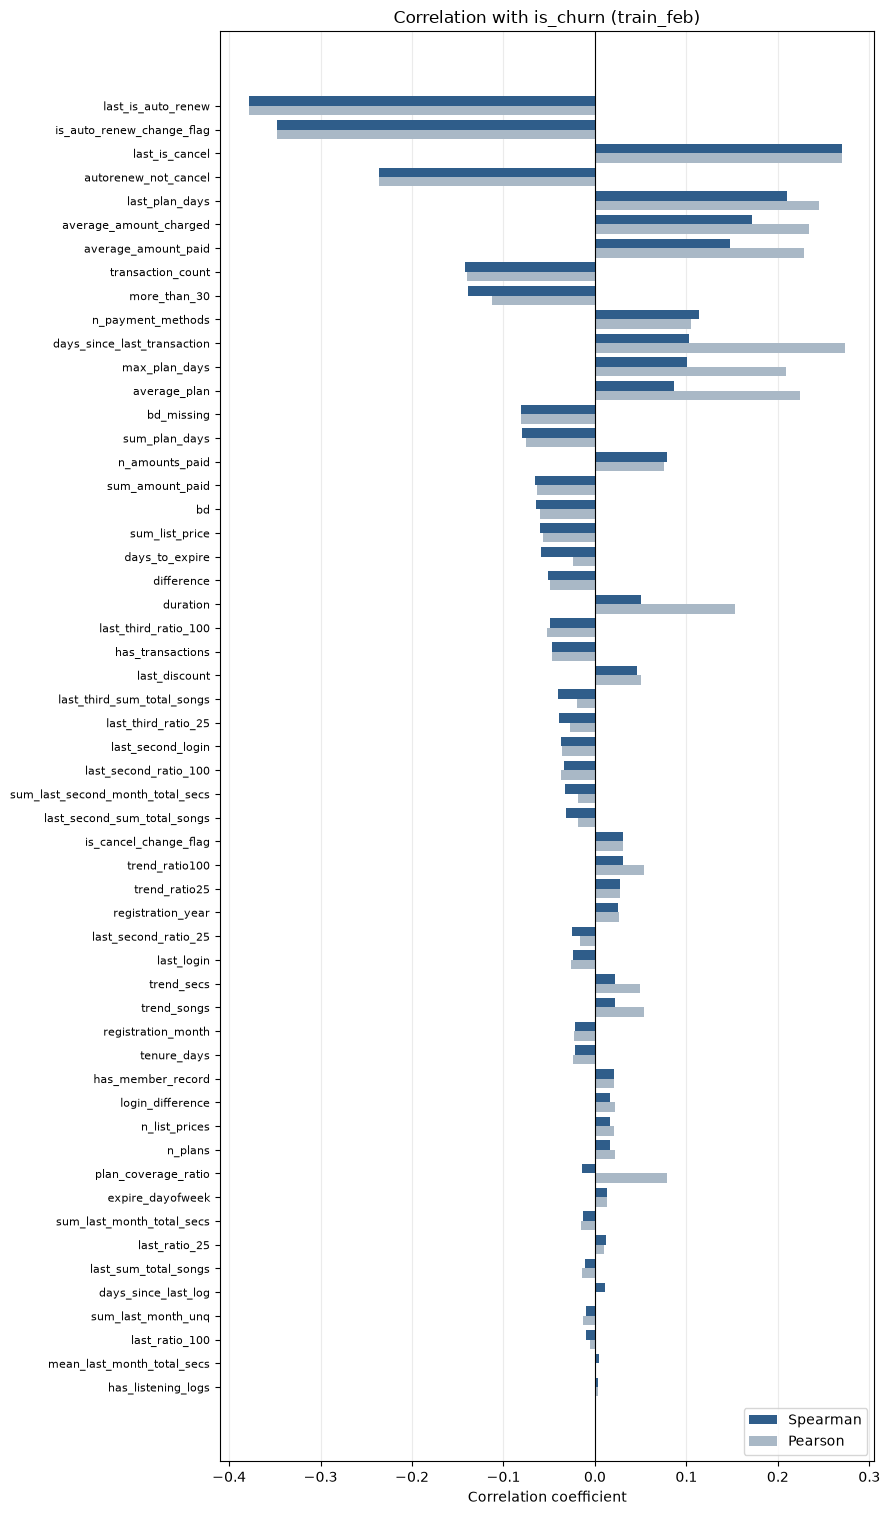

In [5]:
from sklearn.metrics import roc_auc_score


def univariate_auc(values):
    mask = values.notna()
    return roc_auc_score(y[mask], values[mask])


numeric_corr = pd.DataFrame({
    "domain": catalogue.loc[NUMERIC, "domain"],
    "type": catalogue.loc[NUMERIC, "type"],
    "pearson": df[NUMERIC].corrwith(y),
    "spearman": df[NUMERIC].corrwith(y, method="spearman"),
    "roc_auc": [univariate_auc(df[f]) for f in NUMERIC],
})
numeric_corr = numeric_corr.reindex(numeric_corr["spearman"].abs().sort_values(ascending=False).index)
display(numeric_corr.round(4))

order = numeric_corr.index[::-1]
positions = np.arange(len(order))
bar_height = 0.4
fig, ax = plt.subplots(figsize=(9, 0.25 * len(order) + 1.5))
ax.barh(positions + bar_height / 2, numeric_corr.loc[order, "spearman"], bar_height,
        label="Spearman", color="#2f5d8a")
ax.barh(positions - bar_height / 2, numeric_corr.loc[order, "pearson"], bar_height,
        label="Pearson", color="#a9b8c6")
ax.set_yticks(positions, labels=order, fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title=f"Correlation with is_churn ({COHORT})", xlabel="Correlation coefficient")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "churn_numeric_correlations.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## Categorical features and churn

The nominal codes have no order, so a correlation coefficient does not apply. **Cramér's V** (bias-corrected,
0 = independent, 1 = fully determined) measures the strength of association from the contingency table.
The plots show the churn rate of the most frequent levels; rarer levels are pooled into `other` and missing
values appear as `missing`.

,domain,n_levels,cramers_v
feature,,,
last_payment_method_id,transactions,33,0.3792
registered_via,member,5,0.1726
city,member,21,0.0733


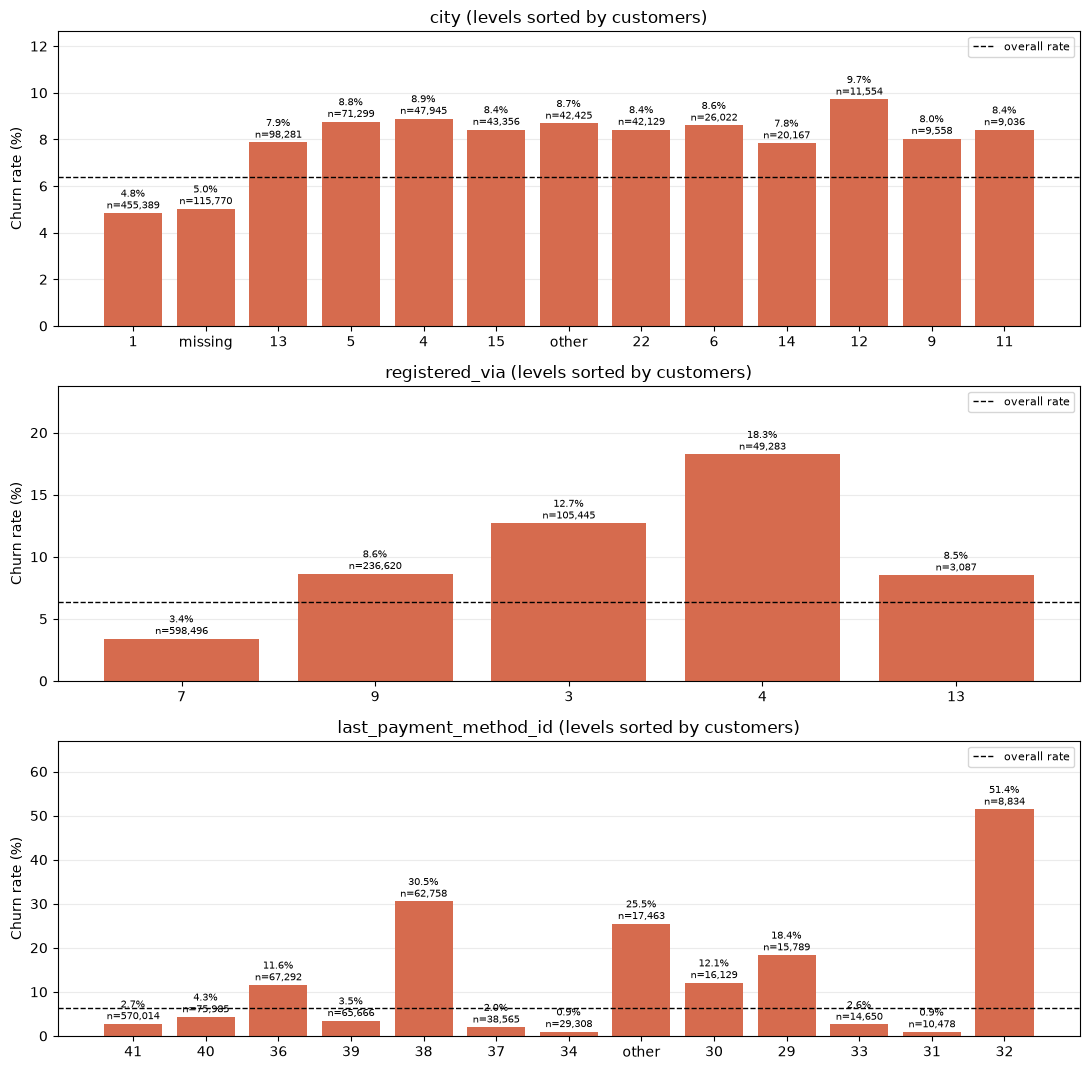

In [6]:
from scipy.stats import chi2_contingency

MAX_LEVELS = 12


def as_levels(series):
    labels = series.astype("Int64").astype("string").fillna("missing")
    top = labels.value_counts().index[:MAX_LEVELS]
    return labels.where(labels.isin(top), "other")


def cramers_v(table):
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    rows, cols = table.shape
    phi2 = max(0.0, chi2 / n - (rows - 1) * (cols - 1) / (n - 1))
    rows_c = rows - (rows - 1) ** 2 / (n - 1)
    cols_c = cols - (cols - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(rows_c - 1, cols_c - 1))


categorical_assoc = pd.DataFrame({
    "domain": catalogue.loc[TYPES["categorical"], "domain"],
    "n_levels": catalogue.loc[TYPES["categorical"], "n_unique"],
    "cramers_v": [
        cramers_v(pd.crosstab(df[f].astype("Int64").astype("string").fillna("missing"), y))
        for f in TYPES["categorical"]
    ],
}).sort_values("cramers_v", ascending=False)
display(categorical_assoc.round(4))

fig, axes = plt.subplots(len(TYPES["categorical"]), 1,
                         figsize=(11, 3.6 * len(TYPES["categorical"])), squeeze=False)
for axis, feature in zip(axes.flat, TYPES["categorical"]):
    levels = as_levels(df[feature])
    stats = y.groupby(levels).agg(["mean", "size"]).sort_values("size", ascending=False)
    bars = axis.bar(stats.index, stats["mean"] * 100, color=churn_colors[1])
    axis.axhline(BASE_RATE * 100, color="black", linestyle="--", linewidth=1, label="overall rate")
    axis.bar_label(bars, labels=[f"{r:.1%}\nn={n:,}" for r, n in zip(stats["mean"], stats["size"])],
                   padding=1, fontsize=7)
    axis.set_title(f"{feature} (levels sorted by customers)")
    axis.set_ylabel("Churn rate (%)")
    axis.set_ylim(0, stats["mean"].max() * 100 * 1.3)
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "churn_categorical_relationships.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## Takeaways

- **Auto-renew is the strongest monotonic signal.** `last_is_auto_renew` (Spearman -0.378), `is_auto_renew_change_flag`
  (-0.348) and `autorenew_not_cancel` (-0.236) are negatively associated with churn, while `last_is_cancel`
  (+0.270) is positively associated: customers whose last payment auto-renews rarely churn.
- **Plan and price.** `last_plan_days` (Spearman +0.210, ROC AUC 0.569), `average_amount_charged` (+0.172, AUC 0.699)
  and `average_amount_paid` (+0.148, AUC 0.669) go with higher churn. Payment history goes the other way:
  `transaction_count` (-0.142) and `more_than_30` (-0.139) are higher for customers who stay.
- **Listening logs are individually weak.** No listening feature exceeds |Spearman| = 0.05 (the largest is
  `last_third_ratio_100`, -0.049).
- **Nominal codes.** Cramér's V is 0.379 for `last_payment_method_id` (33 levels), 0.173 for `registered_via` and 0.073
  for `city`. Payment method 41 (570,014 customers) churns at 2.7 %, method 38 at 30.5 % and method 32 at 51.4 %
  (8,834 customers); `registered_via` 7 churns at 3.4 % while 4 churns at 18.3 %; city 1 churns at 4.8 % against
  7.8-9.7 % in the other large cities.

---
**Previous:** `07_feature_catalogue_and_target.ipynb` · **Next:** `09_binary_discrete_continuous_vs_churn.ipynb`